# Challenge: Residual Connections in a Deep CNN

**ARTE 4110U · Individual challenge**

Implement a convolutional block and use it to build a deep CNN for **CIFAR-10** (32 × 32 color images, 10 classes). Compare the network with and without residual connections.

Complete all **TODOs**, plot and interpret your results, and submit the completed `.ipynb` **with its outputs** on Canvas. Include an AI-use disclosure. Data loading and a training scaffold are provided. A GPU is recommended; you may use Google Colab.

## 1. Setup and data
The code uses 4,000 training images and 1,000 validation images. Both networks use the same data and training settings. Run all cells in order.

In [1]:
import copy, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

transform = transforms.ToTensor()
full_train = datasets.CIFAR10("./data", train=True, download=True, transform=transform)
train_set, val_set, _ = random_split(full_train, [4000, 1000, 45000],
                                     generator=torch.Generator().manual_seed(42))
val_loader = DataLoader(val_set, batch_size=128, shuffle=False)
def make_train_loader():
    return DataLoader(train_set, batch_size=128, shuffle=True,
                      generator=torch.Generator().manual_seed(123))
print(f"Train: {len(train_set)}, validation: {len(val_set)}")

Device: cuda


100%|██████████| 170M/170M [22:46<00:00, 125kB/s]


Train: 4000, validation: 1000


## 2. Implement the residual block

Implement the **pre-activation** branch used in class:

`input → BN → ReLU → 3×3 Conv → BN → ReLU → 3×3 Conv`

- The first convolution maps `in_channels` to `out_channels`; the second maps `out_channels` to `out_channels`. Both use stride 1, padding 1 and `bias=False`.
- Create `bn1` for `in_channels`, `bn2` for `out_channels`, and name the convolutions `conv1` and `conv2`.
- Create a shortcut called `shortcut`: use `nn.Identity()` if the channel counts match; otherwise, use a **1 × 1 convolution**, stride 1, with `bias=False`, to map `in_channels` to `out_channels`. Create it in both model versions so their initial weights can be matched.
- If `use_skip=True`, add the shortcut output to the convolutional branch output. If `False`, return only the branch output; do not use the shortcut.
- Do not apply ReLU after the second convolution or the addition.

The 1 × 1 convolution changes the shortcut's channel count so its output can be added element by element to the branch output.

In [2]:

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, use_skip):
        super().__init__()
        self.use_skip = use_skip

        self.bn1 = nn.BatchNorm2d(in_channels)
        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, stride=1, padding=1, bias=False
        )

        self.bn2 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, stride=1, padding=1, bias=False
        )

        if in_channels == out_channels:
            self.shortcut = nn.Identity()
        else:
            self.shortcut = nn.Conv2d(
                in_channels, out_channels,
                kernel_size=1, stride=1, bias=False
            )

    def forward(self, x):
        out = self.bn1(x)
        out = torch.relu(out)
        out = self.conv1(out)

        out = self.bn2(out)
        out = torch.relu(out)
        out = self.conv2(out)

        if self.use_skip:
            out = out + self.shortcut(x)

        return out


### Check your block
This cell checks both matching channels and a channel increase. It also checks the shortcut type and the addition.

In [3]:
set_seed(1)
for in_c, out_c in [(16, 16), (16, 32)]:
    plain_block = ConvBlock(in_c, out_c, False).eval()
    residual_block = ConvBlock(in_c, out_c, True).eval()
    residual_block.load_state_dict(plain_block.state_dict())
    x = torch.randn(4, in_c, 14, 14)
    with torch.no_grad():
        plain_out = plain_block(x)
        residual_out = residual_block(x)
        shortcut_out = residual_block.shortcut(x)
    assert plain_out.shape == residual_out.shape == (4, out_c, 14, 14)
    assert torch.allclose(residual_out, plain_out + shortcut_out, atol=1e-6)
    if in_c == out_c:
        assert isinstance(residual_block.shortcut, nn.Identity)
        assert torch.allclose(shortcut_out, x)
    else:
        projection = residual_block.shortcut
        assert isinstance(projection, nn.Conv2d)
        assert projection.kernel_size == (1, 1) and projection.stride == (1, 1)
        assert projection.in_channels == in_c and projection.out_channels == out_c
        assert projection.bias is None
    print(f"{in_c} → {out_c} channels: checks passed")

16 → 16 channels: checks passed
16 → 32 channels: checks passed


## 3. Build the CNN

Implement `DeepCNN` using your `ConvBlock` and the following architecture:

1. **Input:** `[batch, 3, 32, 32]` color images.
2. **Stem:** 3 × 3 convolution, 3 → 16 channels, stride 1, padding 1, `bias=False`.
3. **Six blocks:** `16 → 16`, `16 → 16`, `16 → 16`, `16 → 32`, `32 → 32`, `32 → 32`. Pass the network's `use_skip` argument to each block. All blocks keep the 32 × 32 spatial size.
4. **Classifier:** batch normalization for 32 channels, ReLU, global average pooling to 1 × 1, flatten, and a linear layer from 32 to 10 outputs.

Return the 10 **logits** for each image, without softmax. `nn.Sequential` can hold the six blocks; `nn.AdaptiveAvgPool2d(1)` can perform global average pooling.

In [4]:

class DeepCNN(nn.Module):
    def __init__(self, use_skip):
        super().__init__()

        self.stem = nn.Conv2d(
            3, 16, kernel_size=3,
            stride=1, padding=1, bias=False
        )

        self.blocks = nn.Sequential(
            ConvBlock(16, 16, use_skip),
            ConvBlock(16, 16, use_skip),
            ConvBlock(16, 16, use_skip),
            ConvBlock(16, 32, use_skip),
            ConvBlock(32, 32, use_skip),
            ConvBlock(32, 32, use_skip)
        )

        self.bn = nn.BatchNorm2d(32)
        self.relu = nn.ReLU()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(32, 10)

    def forward(self, x):
        x = self.stem(x)
        x = self.blocks(x)
        x = self.bn(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.flatten(x)
        x = self.fc(x)

        return x


### Check and initialize the models

The next cell creates both versions, copies the initial weights, and checks their output shapes. The convolutional branches start with the same weights. Both models contain a projection shortcut for the 16 → 32 block, but only the residual model uses it; it adds trainable weights to the active path of that model.

In [5]:
set_seed(42)
plain = DeepCNN(use_skip=False)
residual = DeepCNN(use_skip=True)
residual.load_state_dict(copy.deepcopy(plain.state_dict()))

# Evaluation mode avoids updating batch-normalization statistics during the check.
for name, model in [("Plain", plain), ("Residual", residual)]:
    model.eval()
    with torch.no_grad():
        output = model(torch.randn(4, 3, 32, 32))
    assert output.shape == (4, 10), f"{name} output shape: {output.shape}"
    print(f"{name} output: {tuple(output.shape)}; parameters: {sum(p.numel() for p in model.parameters())}")

assert all(torch.equal(a, b) for a, b in zip(plain.state_dict().values(), residual.state_dict().values()))
print("Output shape and initial-weight checks passed.")

Plain output: (4, 10); parameters: 66394
Residual output: (4, 10); parameters: 66394
Output shape and initial-weight checks passed.


## 4. Complete training and evaluation

Complete the TODOs in the training and evaluation functions. Train each network for **4 epochs**, using Adam (learning rate 0.001) and cross-entropy loss. The provided code uses the same data order and settings for both models.

For each epoch, report:
- **Average cross-entropy loss:** use the sample-weighted average across batches.
- **Accuracy:** number of correctly classified images divided by the number of images.

Calculate both metrics on training and validation data. Use `argmax` over the 10 output logits for predicted classes. In training mode, compute metrics as the model trains; use evaluation mode and disable gradient tracking for validation. The provided history stores `train_loss`, `train_acc`, `val_loss`, and `val_acc` for plotting. A GPU is recommended.

In [6]:

criterion = nn.CrossEntropyLoss()

def evaluate(model, loader):
    model.eval()
    total_loss = correct = count = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            batch_size = y.size(0)
            total_loss += loss.item() * batch_size

            predictions = logits.argmax(dim=1)
            correct += (predictions == y).sum().item()
            count += batch_size

    return total_loss / count, correct / count


def train_model(model, epochs=4):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    history = {
        k: [] for k in
        ("train_loss", "train_acc", "val_loss", "val_acc")
    }

    train_loader = make_train_loader()

    for epoch in range(epochs):
        model.train()
        loss_sum = correct = count = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()

            logits = model(x)
            loss = criterion(logits, y)

            loss.backward()
            optimizer.step()

            batch_size = y.size(0)
            loss_sum += loss.item() * batch_size

            predictions = logits.argmax(dim=1)
            correct += (predictions == y).sum().item()
            count += batch_size

        train_loss = loss_sum / count
        train_acc = correct / count

        val_loss, val_acc = evaluate(model, val_loader)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch+1}: "
            f"train loss {train_loss:.4f}, "
            f"train acc {train_acc:.3f}, "
            f"val loss {val_loss:.4f}, "
            f"val acc {val_acc:.3f}"
        )

    return model, history


start = time.time()

print("PLAIN NETWORK")
plain_trained, plain_history = train_model(plain)

print("\nRESIDUAL NETWORK")
residual_trained, residual_history = train_model(residual)

print(f"Total training time: {(time.time()-start)/60:.1f} minutes")


PLAIN NETWORK
Epoch 1: train loss 2.1400, train acc 0.209, val loss 2.2777, val acc 0.168
Epoch 2: train loss 1.9144, train acc 0.307, val loss 1.9379, val acc 0.279
Epoch 3: train loss 1.7772, train acc 0.367, val loss 1.8931, val acc 0.326
Epoch 4: train loss 1.6620, train acc 0.414, val loss 1.7677, val acc 0.322

RESIDUAL NETWORK
Epoch 1: train loss 2.1359, train acc 0.220, val loss 2.1707, val acc 0.170
Epoch 2: train loss 1.9334, train acc 0.314, val loss 1.9330, val acc 0.299
Epoch 3: train loss 1.7908, train acc 0.368, val loss 2.0938, val acc 0.241
Epoch 4: train loss 1.6921, train acc 0.402, val loss 1.8279, val acc 0.339
Total training time: 0.3 minutes


## 5. Plot the results

Create **two plots**: training loss versus epoch and validation accuracy versus epoch. Each plot must include both networks. Use the history dictionaries returned by the training code.

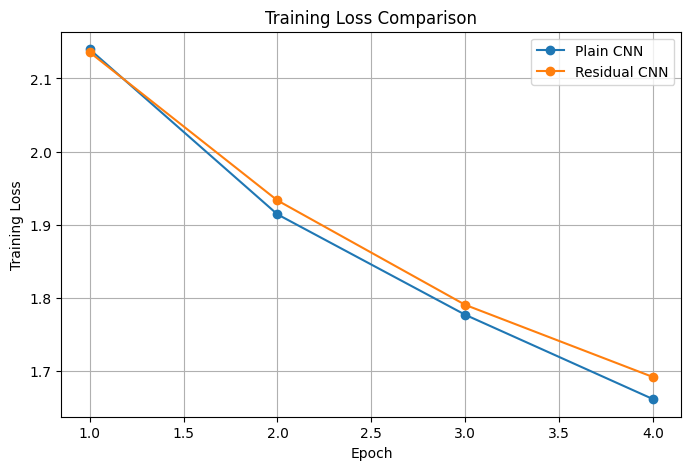

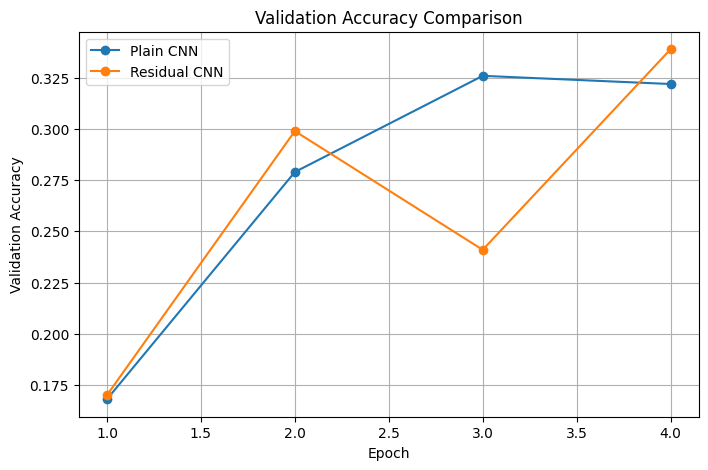

In [7]:
epochs = range(1, len(plain_history["train_loss"]) + 1)

# Plot 1: Training Loss
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    plain_history["train_loss"],
    marker="o",
    label="Plain CNN"
)

plt.plot(
    epochs,
    residual_history["train_loss"],
    marker="o",
    label="Residual CNN"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(True)
plt.show()


# Plot 2: Validation Accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    plain_history["val_acc"],
    marker="o",
    label="Plain CNN"
)

plt.plot(
    epochs,
    residual_history["val_acc"],
    marker="o",
    label="Residual CNN"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy Comparison")
plt.legend()
plt.grid(True)
plt.show()

## 6. Explain your results
Answer briefly using your plots and results. There is no required winner.

1. Compare the training loss and validation accuracy of the two models. Which learned faster in your experiment? Give evidence.
2. Why does the 16 → 32 block need a 1 × 1 convolution on its shortcut? When can the shortcut be an identity? How can a skip connection help gradients reach earlier layers?
3. Why use the same initial branch weights, data, and training settings? The projection is active only in the residual network: how might this limit what you conclude from the comparison?

*Write your answers here.*

### 1. Training loss and validation accuracy

Both models improved throughout the 4 epochs. The Plain CNN
achieved a final training loss of 1.6620 and validation accuracy
of 32.2%, while the Residual CNN achieved a training loss of
1.6921 and validation accuracy of 33.9%.

The Plain CNN learned slightly faster based on training loss,
which was lower from epochs 2 to 4. However, the Residual CNN
achieved slightly better final validation accuracy (33.9%
vs. 32.2%), suggesting better generalization at the end
of this experiment.

### 2. Shortcut connections and gradients

The 16 → 32 block needs a 1 × 1 convolution because the input
has 16 channels while the output has 32. The projection matches
the channel dimensions so both tensors can be added.

An identity shortcut can be used when the input and output
shapes are equal.

Skip connections help gradients reach earlier layers by
providing a direct path during backpropagation, reducing
the vanishing gradient problem.

### 3. Fair comparison and limitations

Using the same initial branch weights, dataset, and training
settings makes the comparison fairer by reducing differences
caused by initialization or training conditions.

However, the 1 × 1 projection is active only in the Residual
CNN. This means the models have slightly different effective
architectures, which limits our ability to attribute performance
differences entirely to skip connections.

Additionally, training for only 4 epochs may not be enough
to establish which architecture performs better overall.

## AI-use disclosure
State whether you used AI tools and, if so, which tools and how you used them.

*Write your disclosure here.*

I used Codex to assist with implementing the
PyTorch code, understanding residual connections and model
training, and organizing the written explanations.